# FNO: локальное обучение

Входы A,n, cos/sin, нормированный k и x,y переносим на равномерную сетку. Каждый слой сочетает усечённую Fourier-свёртку, локальное смешивание каналов и физическую нелинейность. Используются положительная и отрицательная полосы первой FFT-оси и rFFT второй оси; padding смягчает периодическое продолжение на квадратной области.

Выход возвращаем в исходные FEM-узлы для той же consistent комплексной FEM L2 функции потерь. FNO отличается от coefficient-space SNO местом применения нелинейности. [Первичная статья](https://arxiv.org/abs/2010.08895).

**Статичная задача:** геометрия и исходная среда №0 фиксированы; A,n и DG0-материалы одинаковы во всех примерах. Меняются k и θ. Один medium_id=0, разбиение по frequency_id: 670/170/160 частот (5360/1360/1280 полей). 1000 частот × 8 направлений = 8000 полей на полосу. Этот эксперимент проверяет интерполяцию параметров волны на одной среде.

**Результат:** Re(u_scattering), Im(u_scattering), Abs(u_scattering) в исходных FEM-узлах. Модуль вычисляется из восстановленного комплексного поля: `abs = sqrt(real**2 + imag**2)`; отдельный независимый выход для него не обучается. На рисунке три строки — Re, Im, Abs, три столбца — FEM, предсказание и абсолютная ошибка соответствующей величины. Для FEM и модели в каждой строке используется одна шкала цвета.


In [1]:
from pathlib import Path
import sys
ROOT = next(p for p in (Path.cwd(), *Path.cwd().parents) if (p / 'neural_operator').is_dir())
if str(ROOT) not in sys.path:
    sys.path.insert(0, str(ROOT))
from neural_operator import settings as full_settings
from neural_operator.randomized import settings as randomized_settings
POD_METHOD = "randomized"  # Selects the shared run profile; FNO does not use POD.
BAND = "low"  # "low" or "high"; each band has its own trained checkpoint.
if POD_METHOD not in {"full", "randomized"} or BAND not in {"low", "high"}:
    raise ValueError("Choose POD_METHOD full/randomized and BAND low/high")
settings = randomized_settings if POD_METHOD == "randomized" else full_settings
BASE, N_FREQUENCIES, N_DIRECTIONS, DATASET_TAG = (settings.BASE, settings.N_FREQUENCIES,
    settings.N_DIRECTIONS, settings.DATASET_TAG)
DATA_DIR = getattr(settings, f"{BAND.upper()}_DATA_DIR")
RUNS = getattr(settings, f"{BAND.upper()}_RUNS")
import json
import numpy as np
import matplotlib.pyplot as plt
from neural_operator.datasets import load_dataset, write_dataset_info
from neural_operator.plotting import display_table, plot_prediction, plot_history


## Конфигурация и запуск

Первое выполнение обучает модель на локальном CPU. Повторное загружает только завершённый запуск с теми же данными и конфигурацией. `RETRAIN=True` запускает новое обучение; автоматического resume нет. Лучшая эпоха определяется по validation. Лимит эпох не означает сходимость. На каждой модели одинаковы split, seed и максимальный budget эпох, но числа параметров отличаются.

Для сохранённых static-запусков выбран randomized-профиль; `BAND` переключает low/high. Профиль влияет на каталог результатов, а не на Fourier-слои. Рисунок использует тот же test-пример, что и SVD-SNO: ближайший к медианной SVD-SNO ошибке, без отбора по качеству FNO.

`DEVICE` автоматически выбирает MPS на совместимом Mac и CPU в контейнере. Сохранённые веса загружаются на доступное устройство с проверкой данных и настроек обучения; исходное устройство обучения остаётся в `metrics.json`. Для нового запуска CPU используется при недоступности MPS.


In [2]:
from dataclasses import asdict
import torch
from neural_operator.training import TrainConfig, run_experiment, load_predictor, dataset_fingerprint
METHOD = 'fno'
RETRAIN = False
DEVICE = 'mps' if torch.backends.mps.is_available() else 'cpu'
CONFIG = TrainConfig(method=METHOD, epochs=200, batch_size=32, width=24, depth=3,
                     rank=48, input_rank=32, resolution=32, modes=8, seed=42, threads=2, pod_method=POD_METHOD, device=DEVICE)
dataset = load_dataset(DATA_DIR, mmap=True)
OUT = RUNS / METHOD
if (OUT / 'model.pt').exists() and not RETRAIN:
    # Portable inference: weights trained on MPS also load on a CPU kernel.
    metrics = json.loads((OUT / 'metrics.json').read_text())
    requested = asdict(CONFIG)
    saved_config = dict(metrics['config'])
    requested.pop('device')
    saved_config.pop('device')
    if requested != saved_config or metrics['dataset_fingerprint'] != dataset_fingerprint(dataset):
        raise ValueError('Saved FNO run differs from the requested settings/data; choose another OUT or RETRAIN.')
    predictor = load_predictor(OUT / 'model.pt', device=DEVICE)
    history = json.loads((OUT / 'history.json').read_text())
    print('Loaded completed run; training device:', metrics['config']['device'], '; inference device:', DEVICE)
else:
    predictor, metrics, history = run_experiment(dataset, OUT, CONFIG, retrain=RETRAIN)
print(json.dumps(metrics, indent=2, ensure_ascii=False))


Loaded completed run; training device: mps ; inference device: cpu
{
  "method": "fno",
  "field": "scattered",
  "metric": "consistent_complex_FEM_L2",
  "dataset_fingerprint": "786ee3849e909083d98213653affa47907312d0f626e8a60da76e88c70de0ca5",
  "config": {
    "method": "fno",
    "epochs": 200,
    "batch_size": 32,
    "learning_rate": 0.002,
    "width": 24,
    "depth": 3,
    "rank": 48,
    "input_rank": 32,
    "target_projection_error": 0.01,
    "pod_method": "randomized",
    "resolution": 32,
    "modes": 8,
    "padding": 8,
    "patience": 50,
    "min_epochs": 50,
    "seed": 42,
    "threads": 2,
    "device": "mps"
  },
  "train_samples": 5360,
  "val_samples": 1360,
  "test_samples": 1280,
  "split_strategy": "frequency",
  "physical_media": 1,
  "split_groups": {
    "train": 670,
    "validation": 170,
    "test": 160
  },
  "completed_epochs": 142,
  "best_epoch": 92,
  "best_val_fem_l2": 0.016689817936104887,
  "stop_reason": "validation_plateau",
  "parameters"

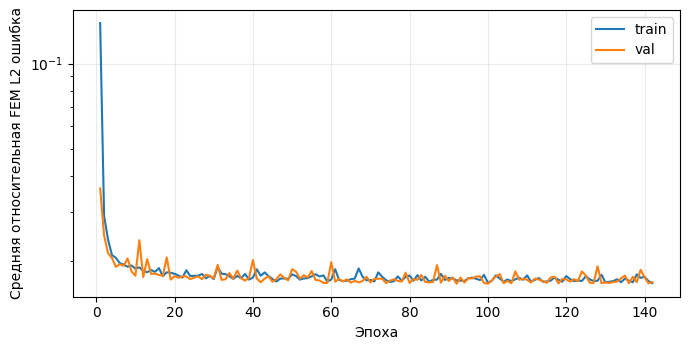

method,mean,median,p95,max,best_epoch,epochs,parameters
fno,0.016599,0.016329,0.019505,0.022305,92,142,445010


In [3]:
figure = plot_history(history)
figure.savefig(OUT / 'history.png', dpi=160)
plt.show()
display_table([{'method': METHOD, **metrics['test_fem_l2'], 'best_epoch': metrics['best_epoch'],
                'epochs': metrics['completed_epochs'], 'parameters': metrics['parameters']}])


In [4]:
from neural_operator.diagnostics import transfer_diagnostics
rows = [r for r in transfer_diagnostics(dataset, resolution=CONFIG.resolution) if r['grid'] == 'uniform']
display_table(rows)


grid,resolution,field,mean_fem_l2,p95_fem_l2
uniform,32,A,0.0066646,0.0066646
uniform,32,n,0.032489,0.032489
uniform,32,u_scat,0.026247,0.028336


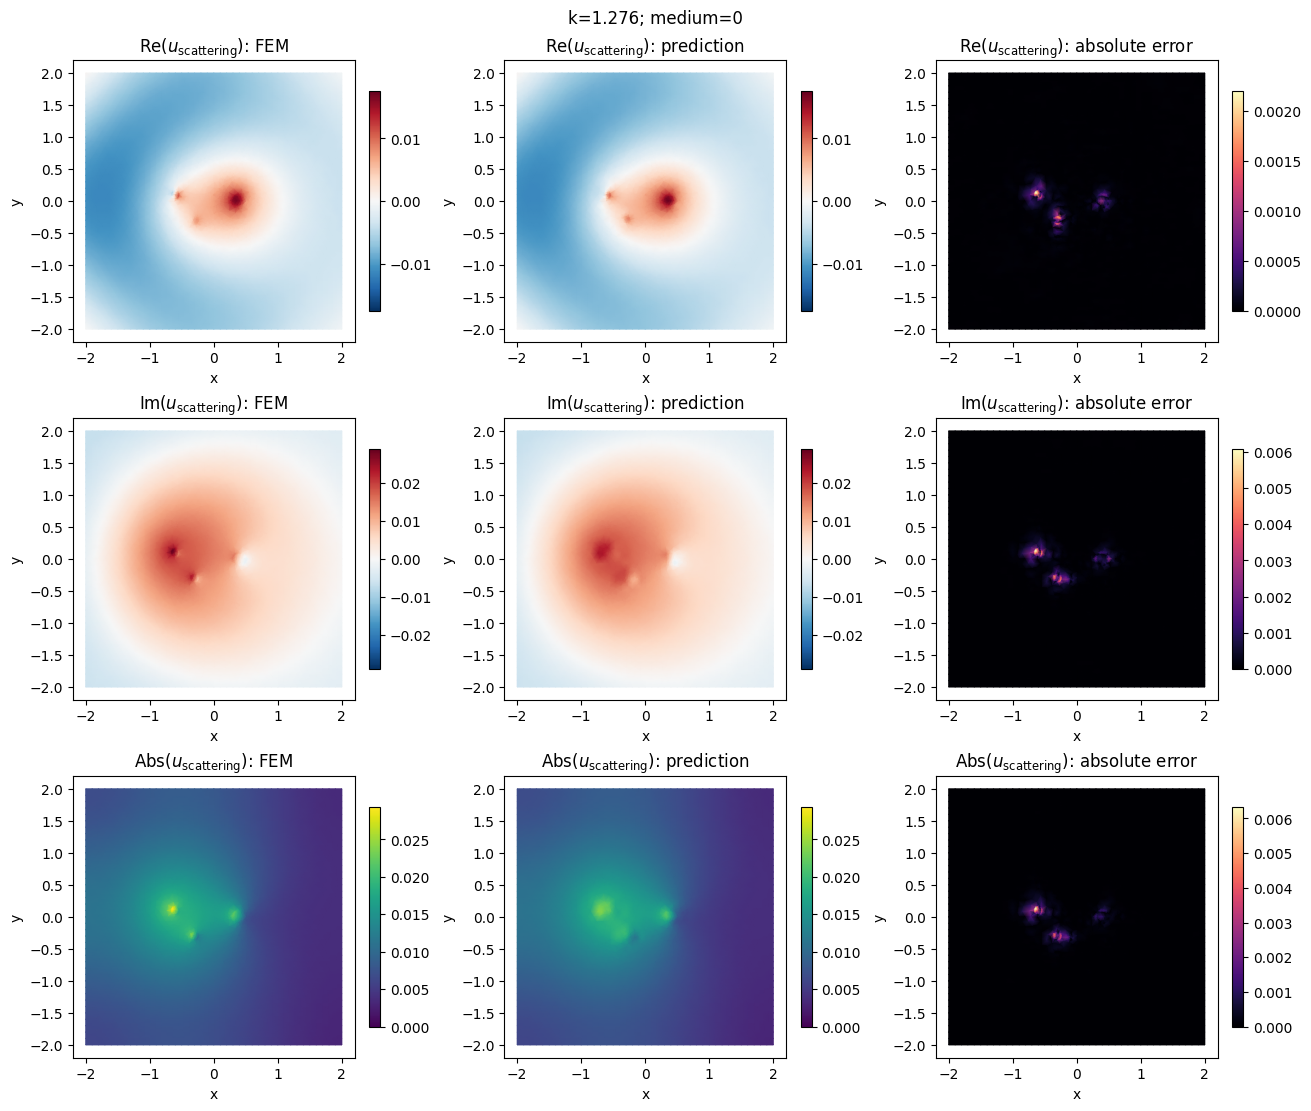

Self-contained checkpoint: /workspace/multiscale-fem-scattering/neural_operator/randomized/runs/low_frequency_static_1000x8/fno/model.pt


In [5]:
# Re, Im и Abs: FEM / предсказание / абсолютная ошибка.
test = dataset.split_indices()[2]
# Use the SVD-SNO example for a paired comparison on the same held-out field.
with np.load(RUNS / 'svd' / 'test_predictions.npz') as reference_run:
    np.testing.assert_array_equal(reference_run['indices'], test)
    reference_errors = reference_run['fem_l2']
    position = int(np.argmin(np.abs(reference_errors - np.median(reference_errors))))
index = int(test[position])
prediction = predictor.predict_dataset(dataset, [index])[0]
figure = plot_prediction(dataset, index, prediction)
figure.savefig(OUT / 'prediction.png', dpi=160)
plt.show()
print('Self-contained checkpoint:', OUT / 'model.pt')


Модель, базисы, нормализация, геометрия и архитектура находятся в одном `model.pt`; история и метрики сохранены рядом. Отдельный [Inference.ipynb](../notebooks/Inference.ipynb) загружает этот файл в чистом ядре. Сопоставление всех методов: [Comparison.ipynb](../notebooks/Comparison.ipynb). Расширенный набор содержит 1000 частот × 8 направлений. Малый train loss не подтверждает перенос на новые среды; результаты старого пилота сохранены в docs/local_results.md.
